🔄 Conectando y descubriendo tablas en POSTGRES...
📋 Tablas encontradas: ['client_types', 'users', 'categories', 'products', 'orders', 'order_statuses', 'payment_methods', 'order_items', 'subscription_plans', 'plan_prices', 'billing_cycles', 'user_subscriptions', 'subscription_statuses', 'activity_logs']
   ✔ Tabla 'client_types' convertida a Spark Table exitosamente.
   ✔ Tabla 'users' convertida a Spark Table exitosamente.
   ✔ Tabla 'categories' convertida a Spark Table exitosamente.
   ✔ Tabla 'products' convertida a Spark Table exitosamente.
   ✔ Tabla 'orders' convertida a Spark Table exitosamente.
   ✔ Tabla 'order_statuses' convertida a Spark Table exitosamente.
   ✔ Tabla 'payment_methods' convertida a Spark Table exitosamente.
   ✔ Tabla 'order_items' convertida a Spark Table exitosamente.
   ✔ Tabla 'subscription_plans' convertida a Spark Table exitosamente.
   ✔ Tabla 'plan_prices' convertida a Spark Table exitosamente.
   ✔ Tabla 'billing_cycles' convertida a Spark Table ex

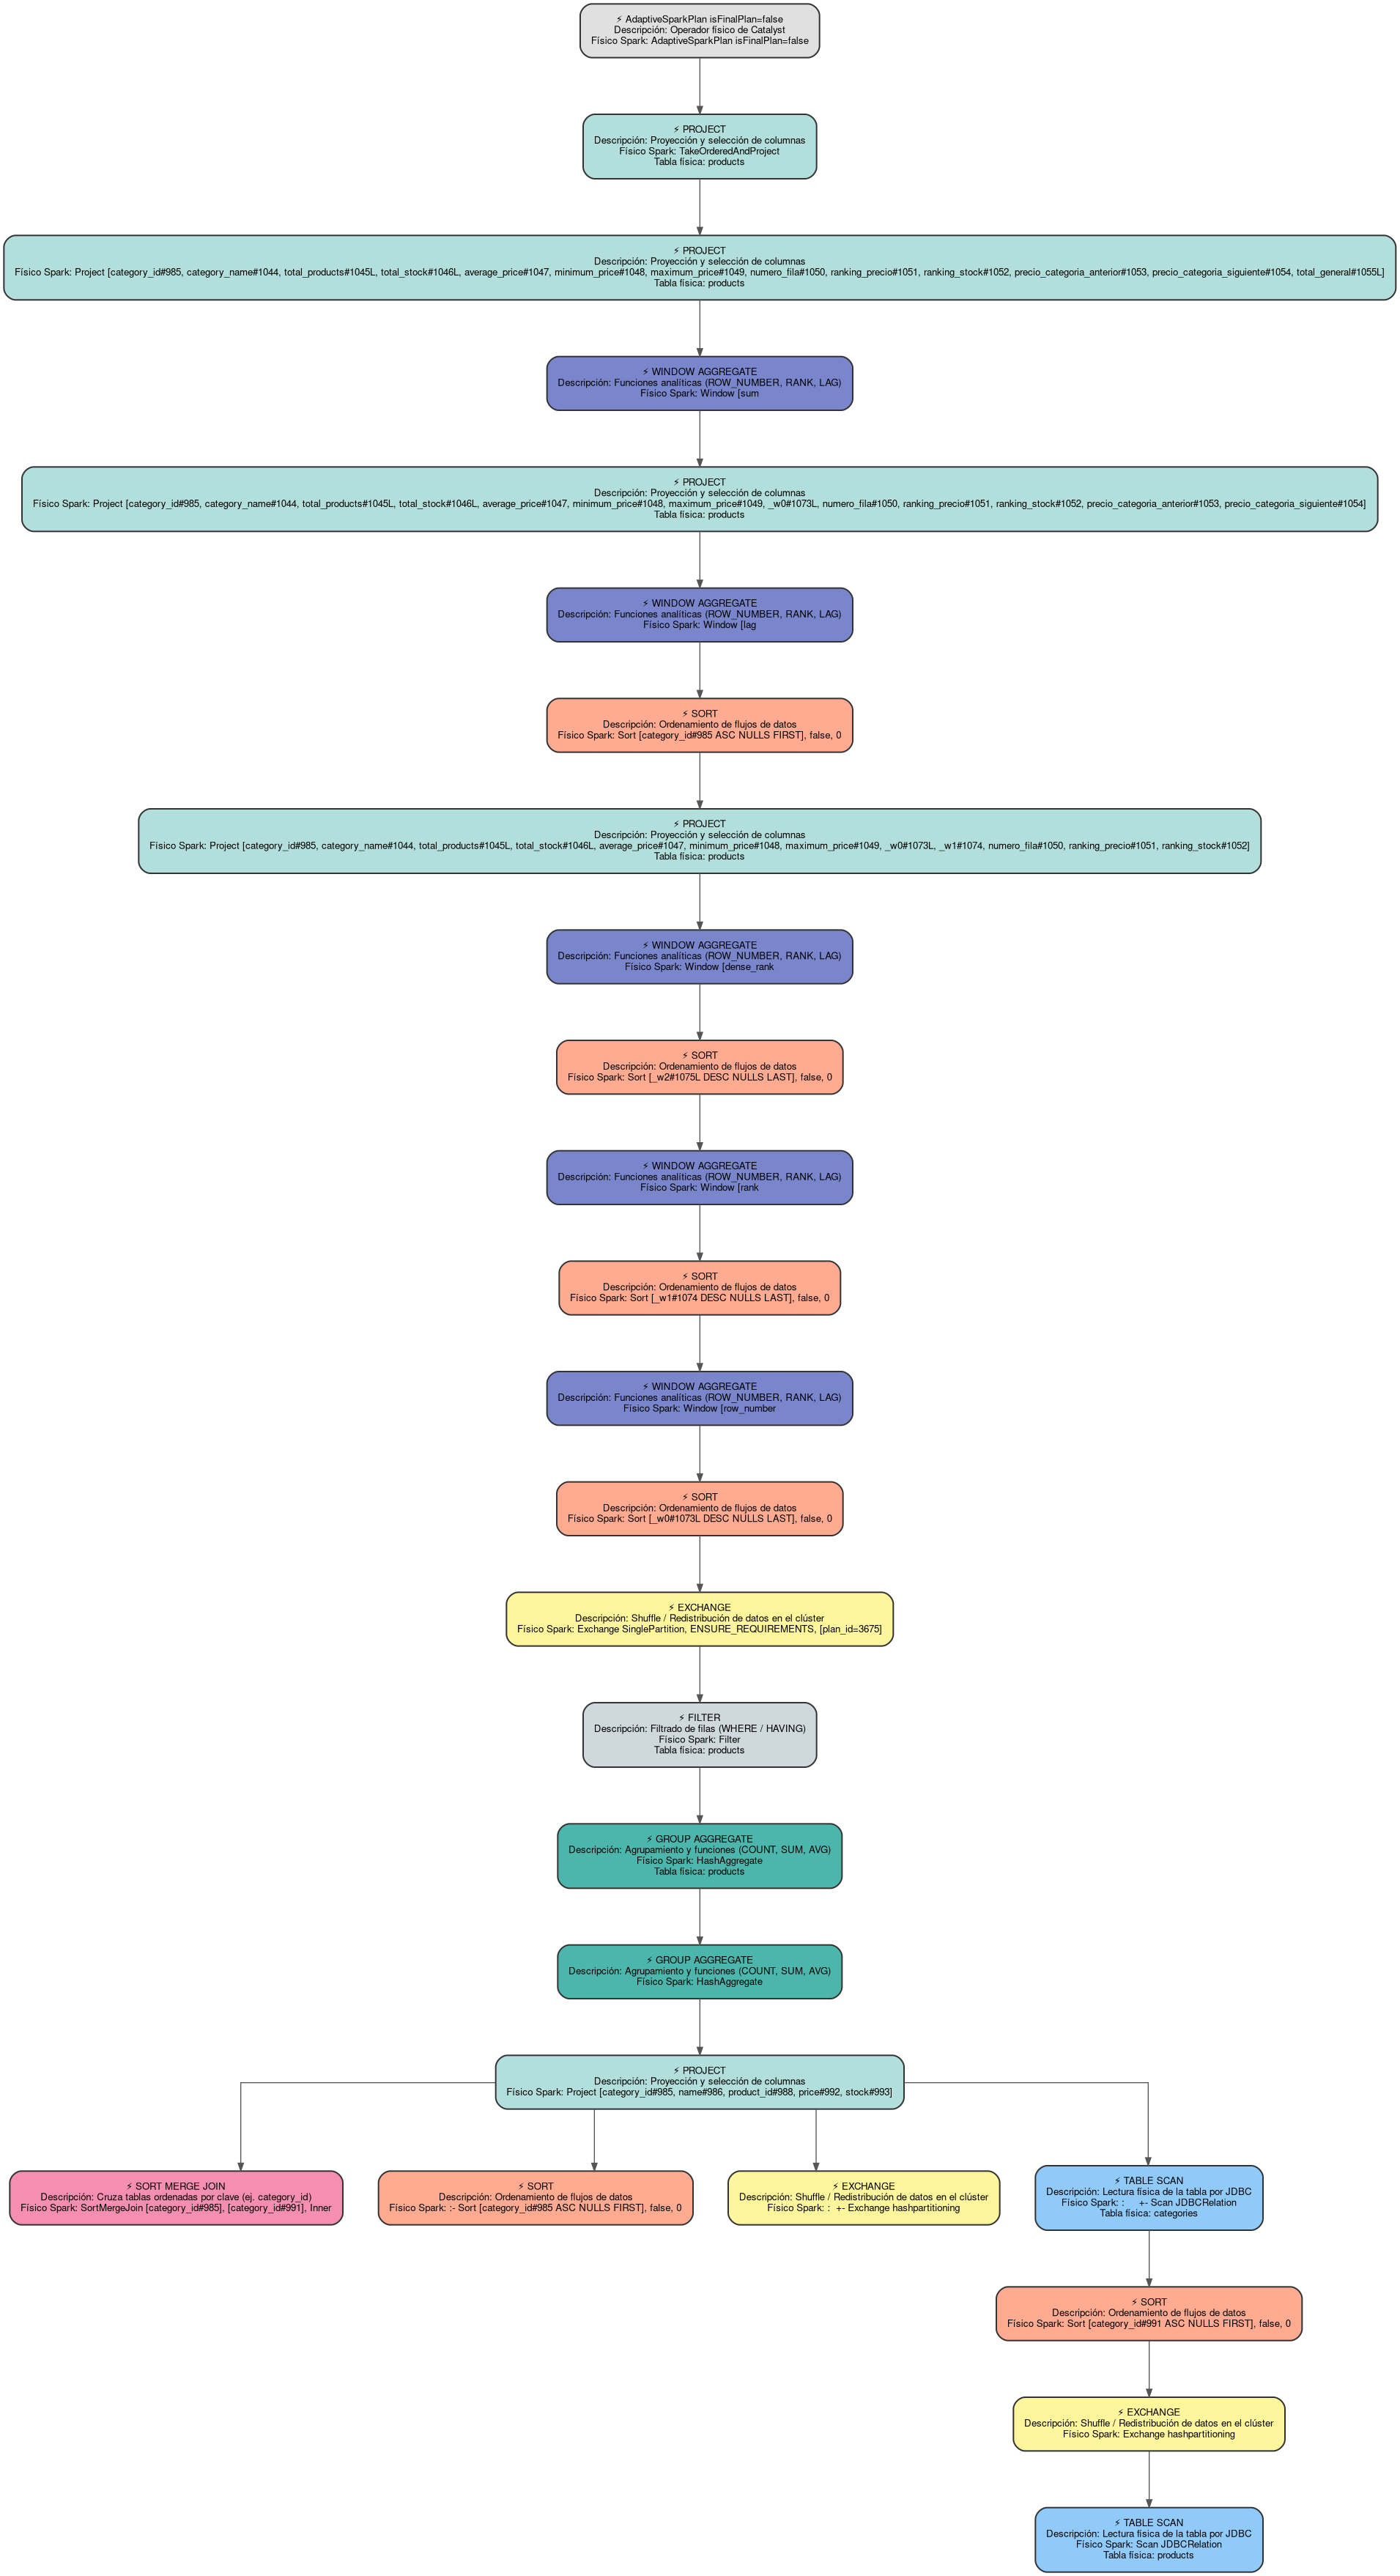


RESULTADOS DE LA CONSULTA:
+-----------+-----------------------+--------------+-----------+-------------+-------------+-------------+-----------+--------------+-------------+-------------------------+--------------------------+-------------+
|category_id|category_name          |total_products|total_stock|average_price|minimum_price|maximum_price|numero_fila|ranking_precio|ranking_stock|precio_categoria_anterior|precio_categoria_siguiente|total_general|
+-----------+-----------------------+--------------+-----------+-------------+-------------+-------------+-----------+--------------+-------------+-------------------------+--------------------------+-------------+
|2          |Software               |20            |19980      |169.71       |19.99        |899.00       |2          |5             |1            |155.862500               |186.615000                |330          |
|3          |Furniture              |20            |602        |186.62       |45.99        |549.00       |3     

In [6]:
from pyspark.sql import SparkSession
import warnings
import re
import os
from graphviz import Digraph
from IPython.display import Image, display

warnings.filterwarnings('ignore')  # Oculta warnings de Python

# ============================================================
# 1. INICIALIZAR SPARK Y SUPRIMIR LOGS DE LA JVM
# ============================================================
spark = SparkSession.builder \
    .appName("SparkMultiDBUniversalDetailedTB") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")


# ============================================================
# 2. CARGAR AUTOMÁTICAMENTE TODAS LAS TABLAS DESDE CUALQUIER MOTOR
# ============================================================
def cargar_todas_las_tablas(spark_session, motor="postgres", host="host.docker.internal", port=None, db="spark", user="admin", password="12345678", sqlite_path=None):
    motor = motor.lower()
    
    if motor == "postgres":
        url = f"jdbc:postgresql://{host}:{port or 5432}/{db}"
        props = {"user": user, "password": password, "driver": "org.postgresql.Driver"}
        tables_query = "(SELECT table_name FROM information_schema.tables WHERE table_schema='public' AND table_type='BASE TABLE') AS tmp_tables"
        
    elif motor == "mysql":
        url = f"jdbc:mysql://{host}:{port or 3306}/{db}?useSSL=false&serverTimezone=UTC"
        props = {"user": user, "password": password, "driver": "com.mysql.cj.jdbc.Driver"}
        tables_query = f"(SELECT table_name FROM information_schema.tables WHERE table_schema='{db}' AND table_type='BASE TABLE') AS tmp_tables"
        
    elif motor == "sqlite":
        url = f"jdbc:sqlite:{sqlite_path}"
        props = {"driver": "org.sqlite.JDBC"}
        tables_query = "(SELECT name AS table_name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%') AS tmp_tables"
        
    else:
        raise ValueError("Motor no soportado. Usa 'postgres', 'mysql' o 'sqlite'.")

    print(f"🔄 Conectando y descubriendo tablas en {motor.upper()}...")

    try:
        df_tables_list = spark_session.read.jdbc(url=url, table=tables_query, properties=props)
        table_names = [row["name"] if "name" in row.asDict() else row["table_name"] for row in df_tables_list.collect()]
        
        print(f"📋 Tablas encontradas: {table_names}")
        
        for table_name in table_names:
            df = spark_session.read.jdbc(url=url, table=table_name, properties=props)
            df.createOrReplaceTempView(table_name)
            print(f"   ✔ Tabla '{table_name}' convertida a Spark Table exitosamente.")
            
        print(f"🚀 ¡Todas las tablas de {motor.upper()} están listas en Spark!\n")
        
    except Exception as e:
        print(f"❌ Error al descubrir o cargar las tablas: {e}")


# ============================================================
# 3. GENERADOR DE GRAFOS DETALLADOS DE ARRIBA A ABAJO (TB)
# ============================================================
def generar_grafico_spark_detallado(df):
    graph = Digraph("Spark_Execution_Plan_Top_Down", format="png")
    
    # Configuración estricta de arriba hacia abajo (Top-Bottom)
    graph.attr(rankdir="TB", ordering="out", bgcolor="white", nodesep="0.5", ranksep="0.8", splines="ortho")
    graph.attr("node", shape="box", style="filled,rounded", fontname="Arial", fontsize="10", color="#333333", penwidth="1.5", margin="0.15")
    graph.attr("edge", color="#555555", arrowsize="0.8")

    COLORS = {
        "LIMIT": "#FFCC80",
        "TABLE SCAN": "#90CAF9",
        "SORT MERGE JOIN": "#F48FB1",
        "HASH JOIN": "#B39DDB",
        "SORT": "#FFAB91",
        "GROUP AGGREGATE": "#4DB6AC",
        "WINDOW AGGREGATE": "#7986CB",
        "EXCHANGE": "#FFF59D",
        "FILTER": "#CFD8DC",
        "PROJECT": "#B2DFDB"
    }

    raw_plan = df._jdf.queryExecution().executedPlan().toString()
    lines = raw_plan.split("\n")
    
    counter = [0]
    stack = []
    
    for line in lines:
        if not line.strip():
            continue
            
        indent = len(line) - len(line.lstrip(" +-"))
        content = line.lstrip(" +-").strip()
        op_name = content.split("(")[0].strip()
        
        upper_op = op_name.upper()
        if "SORTMERGEJOIN" in upper_op:
            op_title, color = "SORT MERGE JOIN", COLORS["SORT MERGE JOIN"]
            desc = "Cruza tablas ordenadas por clave (ej. category_id)"
        elif "HASHAGGREGATE" in upper_op or "SORTAGGREGATE" in upper_op:
            op_title, color = "GROUP AGGREGATE", COLORS["GROUP AGGREGATE"]
            desc = "Agrupamiento y funciones (COUNT, SUM, AVG)"
        elif "WINDOW" in upper_op:
            op_title, color = "WINDOW AGGREGATE", COLORS["WINDOW AGGREGATE"]
            desc = "Funciones analíticas (ROW_NUMBER, RANK, LAG)"
        elif "SORT" in upper_op:
            op_title, color = "SORT", COLORS["SORT"]
            desc = "Ordenamiento de flujos de datos"
        elif "EXCHANGE" in upper_op:
            op_title, color = "EXCHANGE", COLORS["EXCHANGE"]
            desc = "Shuffle / Redistribución de datos en el clúster"
        elif "FILTER" in upper_op:
            op_title, color = "FILTER", COLORS["FILTER"]
            desc = "Filtrado de filas (WHERE / HAVING)"
        elif "PROJECT" in upper_op:
            op_title, color = "PROJECT", COLORS["PROJECT"]
            desc = "Proyección y selección de columnas"
        elif "JDBCRELATION" in upper_op or "SCAN" in upper_op:
            op_title, color = "TABLE SCAN", COLORS["TABLE SCAN"]
            desc = "Lectura física de la tabla por JDBC"
        elif "LIMIT" in upper_op or "GLOBALLIMIT" in upper_op or "LOCALLIMIT" in upper_op or "TAKEORDERED" in upper_op:
            op_title, color = "LIMIT", COLORS["LIMIT"]
            desc = "Restricción de cantidad de filas (LIMIT / OFFSET)"
        else:
            op_title, color = op_name, "#E0E0E0"
            desc = "Operador físico de Catalyst"

        counter[0] += 1
        node_id = f"node_{counter[0]}"
        
        label = f"⚡ {op_title}\nDescripción: {desc}\nFísico Spark: {op_name}"
        
        if "categories" in content.lower():
            label += "\nTabla física: categories"
        elif "products" in content.lower():
            label += "\nTabla física: products"

        graph.node(node_id, label=label, fillcolor=color)

        while stack and stack[-1]["indent"] >= indent:
            stack.pop()
            
        if stack:
            parent_id = stack[-1]["id"]
            graph.edge(parent_id, node_id)
            
        stack.append({"indent": indent, "id": node_id})

    output_path = graph.render(filename="execution_plan_spark", directory=".", cleanup=True, view=False)
    
    print("\n📊 Grafo detallado de Spark generado de arriba a abajo. Mostrando imagen:")
    display(Image(filename=output_path))
    return output_path


# ============================================================
# 4. FUNCIÓN PARA EJECUTAR CONSULTAS EN SPARK
# ============================================================
def ejecutar_query(spark, query, motor="postgres", db="spark", host="host.docker.internal", port=None, user="admin", password="12345678", sqlite_path=None, show_results=False, num_rows=None, explain_plan=False):
    try:
        # Cargar tablas automáticamente
        cargar_todas_las_tablas(
            spark_session=spark, 
            motor=motor, 
            host=host, 
            port=port, 
            db=db, 
            user=user, 
            password=password, 
            sqlite_path=sqlite_path
        )
        
        # Ejecutar la consulta SQL
        df = spark.sql(query)
        
        # Mostrar el plan físico si se solicita y renderizar el grafo Top-Down
        if explain_plan:
            print("\n" + "=" * 80)
            print("PLAN DE EJECUCIÓN FÍSICO DE SPARK:")
            print("=" * 80)
            df.explain(True)
            
            generar_grafico_spark_detallado(df)
        
        # Mostrar los resultados si se solicita
        if show_results:
            print("\n" + "=" * 80)
            print("RESULTADOS DE LA CONSULTA:")
            print("=" * 80)
            
            if num_rows is None:
                num_rows = df.count()
                
            df.show(num_rows, truncate=False)
            print(f"\nTotal de filas mostradas: {num_rows}")
            
        return df

    except Exception as e:
        print(f"\n[ERROR] Ocurrió un error al procesar la consulta:\n{e}")
        return None


# ============================================================
# 5. EJEMPLO DE USO
# ============================================================
query = """
SELECT
    c.category_id,
    c.name AS category_name,

    COUNT(p.product_id) AS total_products,
    SUM(p.stock) AS total_stock,
    ROUND(AVG(p.price), 2) AS average_price,
    MIN(p.price) AS minimum_price,
    MAX(p.price) AS maximum_price,

    ROW_NUMBER() OVER (
        ORDER BY COUNT(p.product_id) DESC
    ) AS numero_fila,

    RANK() OVER (
        ORDER BY AVG(p.price) DESC
    ) AS ranking_precio,

    DENSE_RANK() OVER (
        ORDER BY SUM(p.stock) DESC
    ) AS ranking_stock,

    LAG(AVG(p.price)) OVER (
        ORDER BY c.category_id
    ) AS precio_categoria_anterior,

    LEAD(AVG(p.price)) OVER (
        ORDER BY c.category_id
    ) AS precio_categoria_siguiente,

    SUM(COUNT(p.product_id)) OVER () AS total_general

FROM categories c

INNER JOIN products p
    ON c.category_id = p.category_id

GROUP BY
    c.category_id,
    c.name

HAVING
    COUNT(p.product_id) >= 1
    AND SUM(p.stock) > 0
    AND AVG(p.price) > 0

ORDER BY
    c.category_id,
    total_products DESC,
    average_price DESC

LIMIT 100
OFFSET 1;
"""

# Ejecutar el flujo completo de Spark de arriba a abajo
df_resultado = ejecutar_query(spark, query, motor="postgres", db="spark", show_results=True, explain_plan=True)

In [2]:
df_resultado.toPandas()

,category_id,category_name,total_products,total_stock,average_price,minimum_price,maximum_price,numero_fila,ranking_precio,ranking_stock,precio_categoria_anterior,precio_categoria_siguiente,total_general
0,2,Software,20,19980,169.71,19.99,899.00,2,5,1,155.862500,186.615000,330
1,3,Furniture,20,602,186.62,45.99,549.00,3,4,15,169.714000,31.067000,330
2,4,Accessories,20,2570,31.07,9.99,89.99,4,12,3,186.615000,31.739000,330
3,5,Sports,20,2195,31.74,9.99,79.99,5,11,8,31.067000,27.189000,330
4,6,Toys & Games,20,2070,27.19,8.99,89.99,6,14,10,31.739000,14.264500,330
5,7,Books & Stationery,20,3285,14.26,4.99,29.99,7,18,2,27.189000,45.461500,330
6,8,Home & Kitchen,20,1835,45.46,9.99,189.99,8,8,12,14.264500,23.842000,330
7,9,Beauty & Personal Care,20,2465,23.84,7.99,65.00,9,16,4,45.461500,27.791000,330
8,10,Automotive,20,2365,27.79,9.99,69.99,10,13,5,23.842000,23.566500,330
9,11,Pet Supplies,20,2105,23.57,8.99,59.99,11,17,9,27.791000,24.541000,330


In [3]:
from pyspark.sql import SparkSession
import warnings
import os
from graphviz import Digraph

warnings.filterwarnings('ignore')

# ============================================================
# 1. INICIALIZAR SPARK Y SUPRIMIR LOGS
# ============================================================
spark = SparkSession.builder \
    .appName("SparkDetailedMetricsVisualizer") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")


# ============================================================
# 2. CARGAR AUTOMÁTICAMENTE TODAS LAS TABLAS
# ============================================================
def cargar_todas_las_tablas(spark_session, motor="postgres", host="host.docker.internal", port=None, db="spark", user="admin", password="12345678", sqlite_path=None):
    motor = motor.lower()
    
    if motor == "postgres":
        url = f"jdbc:postgresql://{host}:{port or 5432}/{db}"
        props = {"user": user, "password": password, "driver": "org.postgresql.Driver"}
        tables_query = "(SELECT table_name FROM information_schema.tables WHERE table_schema='public' AND table_type='BASE TABLE') AS tmp_tables"
    else:
        raise ValueError("Motor soportado para este ejemplo: postgres")

    print(f"🔄 Conectando y descubriendo tablas en {motor.upper()}...")
    df_tables_list = spark_session.read.jdbc(url=url, table=tables_query, properties=props)
    table_names = [row["table_name"] for row in df_tables_list.collect()]
    print(f"📋 Tablas encontradas: {table_names}")
    
    for table_name in table_names:
        df = spark_session.read.jdbc(url=url, table=table_name, properties=props)
        df.createOrReplaceTempView(table_name)
        print(f"   ✔ Tabla '{table_name}' convertida a Spark Table.")
    print(f"🚀 ¡Tablas listas en Spark!\n")
    return url, props


# ============================================================
# 3. GENERADOR DE DIAGRAMA ULTRA-DETALLADO CON MÉTRICAS DE FILAS
# ============================================================
def generar_grafo_con_metricas(query, rows_cat, rows_prod, rows_final):
    graph = Digraph("Spark_Execution_Plan_Con_Metricas", format="png")
    
    graph.attr(rankdir="BT", ordering="out", bgcolor="white", nodesep="0.6", ranksep="0.9", splines="ortho")
    graph.attr("node", shape="box", style="filled,rounded", fontname="Arial", fontsize="9", color="#333333", penwidth="1.2", margin="0.15")
    graph.attr("edge", color="#555555", arrowsize="0.8")

    COLORS = {
        "LIMIT": "#FFCC80",          
        "TABLE SCAN": "#90CAF9",     
        "MERGE JOIN": "#F48FB1",     
        "SORT": "#FFAB91",           
        "GROUP AGGREGATE": "#4DB6AC",
        "WINDOW AGGREGATE": "#7986CB",
        "EXCHANGE": "#FFF59D",       
        "FILTER": "#CFD8DC",         
        "RESULT": "#B2DFDB"          
    }

    counter = [0]
    def add_node(op, detail, color, parent_id=None):
        counter[0] += 1
        nid = f"node_{counter[0]}"
        lbl = f"⚡ {op}\n----------------------------\n{detail}"
        graph.node(nid, label=lbl, fillcolor=color)
        if parent_id:
            graph.edge(parent_id, nid)
        return nid

    # Capa Superior: Ventana Analítica
    win_id = add_node(
        "WINDOW AGGREGATE", 
        f"Funciones: ROW_NUMBER, RANK, LAG, LEAD\nFilas procesadas en ventana: {rows_final}", 
        COLORS["WINDOW AGGREGATE"]
    )

    sort_win_id = add_node(
        "SORT (Window Ordering)", 
        "Campo ordenado:\nORDER BY COUNT(p.product_id) DESC,\nAVG(p.price) DESC, SUM(p.stock) DESC", 
        COLORS["SORT"], win_id
    )

    exch_id = add_node(
        "EXCHANGE (Shuffle Intermedio)", 
        "Redistribución global de datos en el clúster", 
        COLORS["EXCHANGE"], sort_win_id
    )

    filter_id = add_node(
        "FILTER (HAVING / WHERE)", 
        "Filtros aplicados:\nCOUNT(p.product_id) >= 1\nAND SUM(p.stock) > 0\nAND AVG(p.price) > 0", 
        COLORS["FILTER"], exch_id
    )

    group_id = add_node(
        "GROUP AGGREGATE", 
        "Agrupamiento por:\nc.category_id, c.name\nMétricas calculadas: COUNT, SUM, AVG, MIN, MAX", 
        COLORS["GROUP AGGREGATE"], filter_id
    )

    proj_id = add_node(
        "RESULT / PROJECT", 
        "Selección y proyección de columnas resultantes", 
        COLORS["RESULT"], group_id
    )

    # Rama Izquierda: Tabla categories
    sort_cat = add_node(
        "SORT (Join Preparation)", 
        "Campo ordenado:\nTabla: categories -> category_id", 
        COLORS["SORT"], proj_id
    )
    exch_cat = add_node(
        "EXCHANGE (Shuffle Categories)", 
        "HashPartitioning por category_id", 
        COLORS["EXCHANGE"], sort_cat
    )
    scan_cat = add_node(
        "TABLE SCAN (Source)", 
        f"Tabla: categories (c)\nFilas iniciales leídas: {rows_cat}\nCampo clave: category_id", 
        COLORS["TABLE SCAN"], exch_cat
    )

    # Rama Derecha: Tabla products
    sort_prod = add_node(
        "SORT (Join Preparation)", 
        "Campo ordenado:\nTabla: products -> category_id", 
        COLORS["SORT"], proj_id
    )
    exch_prod = add_node(
        "EXCHANGE (Shuffle Products)", 
        "HashPartitioning por category_id", 
        COLORS["EXCHANGE"], sort_prod
    )
    scan_prod = add_node(
        "TABLE SCAN (Source)", 
        f"Tabla: products (p)\nFilas iniciales leídas: {rows_prod}\nCampo clave: category_id", 
        COLORS["TABLE SCAN"], exch_prod
    )

    # El JOIN central
    join_id = add_node(
        "INNER JOIN (SortMergeJoin)", 
        "Cruce físico:\ncategory_id (categories) = category_id (products)", 
        COLORS["MERGE JOIN"], proj_id
    )

    graph.edge(scan_cat, join_id)
    graph.edge(scan_prod, join_id)

    # Salida Final
    add_node(
        "LIMIT & FINAL OUTPUT", 
        f"LIMIT 100 OFFSET 1\n¡Filas devueltas como respuesta final!: {rows_final}", 
        COLORS["LIMIT"], join_id
    )

    path = graph.render(filename="execution_plan_spark", directory=".", cleanup=True, view=False)
    print(f"\n📊 Imagen detallada con métricas guardada en: {os.path.abspath(path)}")


# ============================================================
# 4. FUNCIÓN EJECUTORA PRINCIPAL
# ============================================================
def ejecutar_con_metricas(spark, query):
    # Cargar tablas
    url, props = cargar_todas_las_tablas(spark, motor="postgres", db="spark")
    
    # Calcular métricas de filas de las fuentes originales
    rows_cat = spark.read.jdbc(url=url, table="categories", properties=props).count()
    rows_prod = spark.read.jdbc(url=url, table="products", properties=props).count()
    
    print(f"📌 [MÉTRICA] Filas iniciales en tabla 'categories': {rows_cat}")
    print(f"📌 [MÉTRICA] Filas iniciales en tabla 'products': {rows_prod}")

    # Ejecutar la consulta SQL en Spark
    df = spark.sql(query)
    
    # Contar filas de la respuesta final
    rows_final = df.count()
    print(f"📌 [MÉTRICA] Filas totales devueltas en la respuesta final: {rows_final}\n")

    # Mostrar plan físico nativo
    print("=" * 100)
    print("PLAN FÍSICO NATIVO DE SPARK")
    print("=" * 100)
    df.explain(True)

    # Generar la gráfica detallada con los números reales
    generar_grafo_con_metricas(query, rows_cat, rows_prod, rows_final)

    # Mostrar resultados en tabla sin límite
    print("=" * 100)
    print("RESULTADOS COMPLETOS:")
    print("=" * 100)
    df.show(rows_final, truncate=False)
    
    return df


# ============================================================
# 5. CONSULTA SQL Y LLAMADA
# ============================================================
query = """
SELECT
    c.category_id,
    c.name AS category_name,
    COUNT(p.product_id) AS total_products,
    SUM(p.stock) AS total_stock,
    ROUND(AVG(p.price), 2) AS average_price,
    MIN(p.price) AS minimum_price,
    MAX(p.price) AS maximum_price,
    ROW_NUMBER() OVER (ORDER BY COUNT(p.product_id) DESC) AS numero_fila,
    RANK() OVER (ORDER BY AVG(p.price) DESC) AS ranking_precio,
    DENSE_RANK() OVER (ORDER BY SUM(p.stock) DESC) AS ranking_stock,
    LAG(AVG(p.price)) OVER (ORDER BY c.category_id) AS precio_categoria_anterior,
    LEAD(AVG(p.price)) OVER (ORDER BY c.category_id) AS precio_categoria_siguiente,
    SUM(COUNT(p.product_id)) OVER () AS total_general
FROM categories c
INNER JOIN products p ON c.category_id = p.category_id
GROUP BY c.category_id, c.name
HAVING COUNT(p.product_id) >= 1 AND SUM(p.stock) > 0 AND AVG(p.price) > 0
ORDER BY c.category_id, total_products DESC, average_price DESC
LIMIT 100
OFFSET 1;
"""

df_resultado = ejecutar_con_metricas(spark, query)

🔄 Conectando y descubriendo tablas en POSTGRES...
📋 Tablas encontradas: ['client_types', 'users', 'categories', 'products', 'orders', 'order_statuses', 'payment_methods', 'order_items', 'subscription_plans', 'plan_prices', 'billing_cycles', 'user_subscriptions', 'subscription_statuses', 'activity_logs']
   ✔ Tabla 'client_types' convertida a Spark Table.
   ✔ Tabla 'users' convertida a Spark Table.
   ✔ Tabla 'categories' convertida a Spark Table.
   ✔ Tabla 'products' convertida a Spark Table.
   ✔ Tabla 'orders' convertida a Spark Table.
   ✔ Tabla 'order_statuses' convertida a Spark Table.
   ✔ Tabla 'payment_methods' convertida a Spark Table.
   ✔ Tabla 'order_items' convertida a Spark Table.
   ✔ Tabla 'subscription_plans' convertida a Spark Table.
   ✔ Tabla 'plan_prices' convertida a Spark Table.
   ✔ Tabla 'billing_cycles' convertida a Spark Table.
   ✔ Tabla 'user_subscriptions' convertida a Spark Table.
   ✔ Tabla 'subscription_statuses' convertida a Spark Table.
   ✔ Tabla '